<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Treasury Fiscal Data](https://github.com/Query-farm/vgi-treasury)

Query federal debt, operating cash, deposits, withdrawals and public debt transactions, and discover Fiscal Data endpoint fields.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-treasury/blob/main/notebooks/02_cash_flows_have_different_boundaries.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-treasury/blob/main/notebooks/README.md)


## 02 · Same day and units do not mean the same cash flow

Does net public debt issuance explain the Treasury General Account's daily change?
First reconcile TGA opening and closing balances against the published deposit and
withdrawal totals. Then compare that net cash flow with issues minus redemptions
across all listed security types. They use the same dates and **USD millions**, but
they have different accounting boundaries; agreement is not assumed.

These are original official public responses captured for January 8–12, 2024.
[Provenance](fixtures/discovery-provenance.json) records URLs, parameters, timestamps,
row counts and SHA256 hashes. Recorded rows are preserved; only loopback pagination
envelopes are generated. No synthetic amounts, credentials or real account writes.

### Extend the returned report window

`LAST_REPORT = "2024-01-10"` selects three report days; use **2024-01-12** for the
experiment. The start remains January 8 and the capture remains unchanged. Every
source row in the shared prefix must be identical. Values are daily stock or flow
measures as identified below; month-to-date and fiscal-year-to-date columns are
retained in the source but must not be added to today's flows.

In [1]:
LAST_REPORT = "2024-01-10"  # Experiment: "2024-01-12".

### Run this notebook

Read the saved results on GitHub or choose **Open in Colab** and Run All. Setup installs
the shared base tools, preserving compatible preloaded data/plotting libraries.
Initial packages, verified companions, VGI and the released worker need internet.
The default analysis then uses recorded public Treasury rows over loopback HTTP;
it does not generate synthetic replacement values or contact the official API.

uv supplies the worker's separate Python 3.13+ environment. A fresh preloaded Python
3.12 notebook-only run verifies the common setup path; actual hosted Colab has not
been tested. No source checkout, worker build or real credential is required.

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.30":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.30"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.30":
    raise RuntimeError("Install shared tools v0.3.30, then restart and run all.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from vgi_notebooks.bootstrap import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("treasury")
%matplotlib inline
theme()
session = connect(globals())
connection = session.connection
Path("artifacts").mkdir(exist_ok=True)

from multi_recorded_api import RecordedFiscalSource

source = RecordedFiscalSource()
SOURCE_STAMP = source.manifest["captures"][0]["captured_at_utc"][:10]
PROVENANCE = f"US Treasury Fiscal Data · recorded public rows · captured {SOURCE_STAMP} · released v0.1.0"

if LAST_REPORT not in {"2024-01-10", "2024-01-12"}:
    raise ValueError("LAST_REPORT must be 2024-01-10 or 2024-01-12")
daily = checks = pd.DataFrame()

### Materialize each complete source once

The isolated shared connection begins with no SQL secrets and disallows persistent
ones. This public service requires no key. The helper replaces only documented
Treasury source settings for the worker and restores them on cleanup. Page size
100 deliberately exercises pagination; `max_rows := 0` keeps every bounded match.
The dataset catalog supplies endpoint-specific units before any comparison.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'treasury' (TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-treasury@v0.1.0 vgi-treasury-worker');

,Success


In [5]:
%%sql
CREATE TABLE cash AS SELECT * FROM treasury.main.operating_cash_balance(
 start_date := '2024-01-08',end_date := '{{ LAST_REPORT }}',page_size := 100,max_rows := 0);
CREATE TABLE deposits AS SELECT * FROM treasury.main.deposits_withdrawals(
 start_date := '2024-01-08',end_date := '{{ LAST_REPORT }}',page_size := 100,max_rows := 0);
CREATE TABLE transactions AS SELECT * FROM treasury.main.public_debt_transactions(
 start_date := '2024-01-08',end_date := '{{ LAST_REPORT }}',page_size := 100,max_rows := 0);
CREATE TABLE units AS SELECT * FROM treasury.main.datasets();
SELECT dataset,amount_units,description FROM units
WHERE dataset IN ('operating_cash_balance','deposits_withdrawals','public_debt_transactions') ORDER BY dataset;
SELECT account_type,open_today_bal::VARCHAR AS source_amount_musd,close_today_bal::VARCHAR AS legacy_closing_musd
FROM cash WHERE record_date=DATE '2024-01-08' ORDER BY src_line_nbr;

,account_type,source_amount_musd,legacy_closing_musd
0,Treasury General Account (TGA) Opening Balance,747982,None
1,Total TGA Deposits (Table II),30561,None
2,Total TGA Withdrawals (Table II) (-),19977,None
3,Treasury General Account (TGA) Closing Balance,758566,None


### Select labeled totals instead of summing totals and details

In this capture, **all legacy `close_today_bal` fields are NULL**. The value on the
row labeled “TGA Closing Balance” is carried in `open_today_bal`. We choose that row
explicitly, alongside the separately labeled opening row, rather than replacing a
NULL from another account or inferring an undocumented fallback.

Table II includes detailed categories **and** total rows. Select the two account
labels “Treasury General Account Total Deposits” and “Total Withdrawals”; summing
them with the detail rows would double count. Table III issues and redemptions keep
each distinct source line, including same-named securities and signed adjustments.
The full window contains only those two transaction types, which is checked below.

In [6]:
%%sql
CREATE TABLE daily AS
WITH balances AS (
 SELECT record_date,
 max(open_today_bal) FILTER(WHERE account_type='Treasury General Account (TGA) Opening Balance') AS opening_musd,
 max(open_today_bal) FILTER(WHERE account_type='Treasury General Account (TGA) Closing Balance') AS closing_musd
 FROM cash GROUP BY record_date
), flows AS (
 SELECT record_date,
 max(transaction_today_amt) FILTER(WHERE account_type='Treasury General Account Total Deposits') AS deposits_musd,
 max(transaction_today_amt) FILTER(WHERE account_type='Treasury General Account Total Withdrawals') AS withdrawals_musd
 FROM deposits GROUP BY record_date
), debt AS (
 SELECT record_date,
 sum(transaction_today_amt) FILTER(WHERE transaction_type='Issues') AS issues_musd,
 sum(transaction_today_amt) FILTER(WHERE transaction_type='Redemptions') AS redemptions_musd
 FROM transactions GROUP BY record_date
)
SELECT *,closing_musd-opening_musd AS cash_change_musd,
 deposits_musd-withdrawals_musd AS net_cash_musd,
 issues_musd-redemptions_musd AS net_issuance_musd,
 closing_musd-opening_musd-deposits_musd+withdrawals_musd AS cash_residual_musd
FROM balances JOIN flows USING(record_date) JOIN debt USING(record_date);
SELECT record_date,opening_musd::VARCHAR,closing_musd::VARCHAR,net_cash_musd::VARCHAR,
 net_issuance_musd::VARCHAR,cash_residual_musd::VARCHAR FROM daily ORDER BY record_date;

,record_date,CAST(opening_musd AS VARCHAR),CAST(closing_musd AS VARCHAR),CAST(net_cash_musd AS VARCHAR),CAST(net_issuance_musd AS VARCHAR),CAST(cash_residual_musd AS VARCHAR)
0,2024-01-08,747982,758566,10584,2508,0
1,2024-01-09,758566,749407,-9159,12576,0
2,2024-01-10,749407,727856,-21550,-22336,-1


In [7]:
%%sql daily <<
SELECT record_date,opening_musd::DOUBLE AS opening_musd,closing_musd::DOUBLE AS closing_musd,
 cash_change_musd::DOUBLE AS cash_change_musd,net_cash_musd::DOUBLE AS net_cash_musd,
 net_issuance_musd::DOUBLE AS net_issuance_musd,cash_residual_musd::DOUBLE AS cash_residual_musd
FROM daily ORDER BY record_date;

In [8]:
max_residual = float(daily.cash_residual_musd.abs().max())
prose(
    f"The selected window has **{len(daily)} report days**. The largest absolute TGA accounting "
    f"residual is **{max_residual:g} USD million** at the source's whole-million precision. "
    "The residual is displayed, not forced to zero or treated as a universal tolerance. "
    f"On January 8, net cash is **{daily.iloc[0].net_cash_musd:,.0f} USD million**, "
    f"while net debt issuance is **{daily.iloc[0].net_issuance_musd:,.0f} USD million**. "
    "Cash totals include many receipts and payments; security issuance/redemption is a separate scope. "
    "Their difference alone cannot identify an omitted transaction, a budget deficit or a fiscal cause."
)

The selected window has **3 report days**. The largest absolute TGA accounting residual is **1 USD million** at the source's whole-million precision. The residual is displayed, not forced to zero or treated as a universal tolerance. On January 8, net cash is **10,584 USD million**, while net debt issuance is **2,508 USD million**. Cash totals include many receipts and payments; security issuance/redemption is a separate scope. Their difference alone cannot identify an omitted transaction, a budget deficit or a fiscal cause.

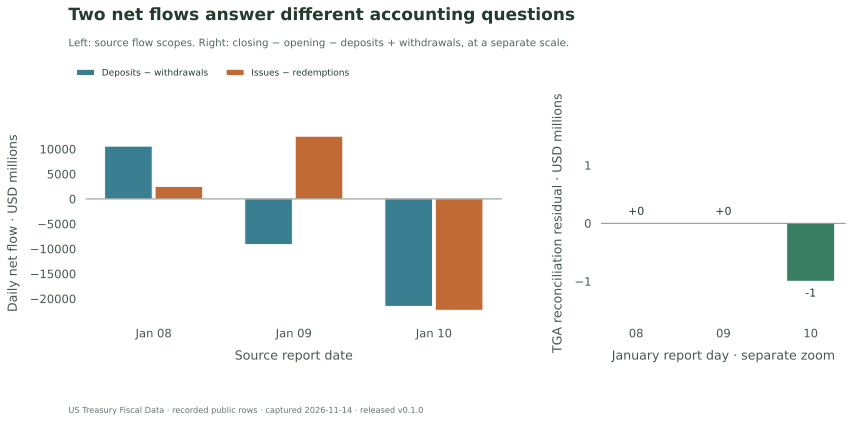

In [9]:
x = np.arange(len(daily))
fig, (ax, residual) = plt.subplots(1, 2, figsize=(12, 6.2), gridspec_kw={"width_ratios": [1.7, 1]})
ax.bar(x - 0.18, daily.net_cash_musd, 0.34, label="Deposits − withdrawals", color="#397F91")
ax.bar(x + 0.18, daily.net_issuance_musd, 0.34, label="Issues − redemptions", color="#C26A35")
ax.axhline(0, color="#66756C", linewidth=0.8)
ax.set_xticks(x, daily.record_date.dt.strftime("%b %d"))
ax.set_ylabel("Daily net flow · USD millions")
ax.set_xlabel("Source report date")
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.07, 0.85), ncol=2, fontsize=9)
residual.bar(x, daily.cash_residual_musd, color="#397D62", width=0.55)
residual.axhline(0, color="#66756C", linewidth=0.8)
residual.set_ylim(-1.65, 1.65)
residual.set_yticks([-1, 0, 1])
residual.set_xticks(x, daily.record_date.dt.strftime("%d"))
residual.set_ylabel("TGA reconciliation residual · USD millions")
residual.set_xlabel("January report day · separate zoom")
for i, value in enumerate(daily.cash_residual_musd):
    residual.text(
        i, value + (0.1 if value >= 0 else -0.12), f"{value:+.0f}", ha="center", va="bottom" if value >= 0 else "top"
    )
finish(
    fig,
    "Two net flows answer different accounting questions",
    "Left: source flow scopes. Right: closing − opening − deposits + withdrawals, at a separate scale.",
    PROVENANCE,
    name=f"daily-boundaries-{LAST_REPORT}",
)

### Verify exact source arithmetic and keep its residual visible

All money stays in exact SQL decimals until chart conversion. We check keys and
labeled row multiplicity before `max` selects one value per date. A bounded residual
of at most one million is an **observed property of these recorded days**, consistent
with separate whole-million reporting; it is not a general reconciliation guarantee.
The original amount strings are independently cast and compared to typed outputs.

In [10]:
%%sql checks <<
SELECT 'Cash keys unique' AS invariant,count(*)=count(DISTINCT struct_pack(d:=record_date,n:=src_line_nbr)) AS passed FROM cash
UNION ALL SELECT 'Deposit keys unique',count(*)=count(DISTINCT struct_pack(d:=record_date,n:=src_line_nbr)) FROM deposits
UNION ALL SELECT 'Debt transaction keys unique',count(*)=count(DISTINCT struct_pack(d:=record_date,n:=src_line_nbr)) FROM transactions
UNION ALL SELECT 'Exactly four labeled cash rows each day',bool_and(n=4) FROM (SELECT record_date,count(*) n FROM cash GROUP BY record_date)
UNION ALL SELECT 'Exactly one selected opening and closing each day',bool_and(n=2 AND kinds=2) FROM
 (SELECT record_date,count(*) n,count(DISTINCT account_type) kinds FROM cash WHERE account_type IN
 ('Treasury General Account (TGA) Opening Balance','Treasury General Account (TGA) Closing Balance') GROUP BY record_date)
UNION ALL SELECT 'Exactly two selected totals each day',bool_and(n=2 AND kinds=2) FROM
 (SELECT record_date,count(*) n,count(DISTINCT account_type) kinds FROM deposits WHERE account_type IN
 ('Treasury General Account Total Deposits','Treasury General Account Total Withdrawals') GROUP BY record_date)
UNION ALL SELECT 'Legacy closing fields stay missing',bool_and(close_today_bal IS NULL) FROM cash
UNION ALL SELECT 'Transactions have only issues and redemptions',bool_and(transaction_type IN ('Issues','Redemptions')) FROM transactions
UNION ALL SELECT 'All endpoints retain USD millions',bool_and(amount_units='USD millions') FROM
 (SELECT amount_units FROM cash UNION ALL SELECT amount_units FROM deposits UNION ALL SELECT amount_units FROM transactions)
UNION ALL SELECT 'Original daily transaction amounts round trip',bool_and(transaction_today_amt=(source_json::JSON->>'transaction_today_amt')::DECIMAL(38,0)) FROM transactions
UNION ALL SELECT 'Recorded cash residual stays within one million',bool_and(abs(cash_residual_musd)<=1) FROM daily
UNION ALL SELECT 'Every cash date survives the join',(SELECT count(*) FROM daily)=(SELECT count(DISTINCT record_date) FROM cash);

In [11]:
display(checks)
assert len(checks) == 12 and checks.passed.notna().all() and checks.passed.all()
requests = source.audit(
    [(name, "2024-01-08", LAST_REPORT, 100, "records") for name in ["cash", "deposits", "transactions"]]
)
prose(
    f"All **{len(checks)} SQL checks** pass. **{requests} local GETs** retrieve the three complete "
    "bounded populations; local displays add no upstream requests."
)
Path("artifacts/daily-audit.json").write_text(
    json.dumps(
        {
            "last_report": LAST_REPORT,
            "requests": requests,
            "daily": connection.execute("SELECT * FROM daily ORDER BY record_date")
            .fetchdf()
            .astype(str)
            .to_dict("records"),
            "counts": {
                t: connection.execute(f"SELECT count(*) FROM {t}").fetchone()[0]
                for t in ["cash", "deposits", "transactions"]
            },
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

,invariant,passed
0,Cash keys unique,True
1,Deposit keys unique,True
2,Debt transaction keys unique,True
3,Exactly four labeled cash rows each day,True
4,Exactly one selected opening and closing each day,True
5,Exactly two selected totals each day,True
6,Legacy closing fields stay missing,True
7,Transactions have only issues and redemptions,True
8,All endpoints retain USD millions,True
9,Original daily transaction amounts round trip,True


All **12 SQL checks** pass. **8 local GETs** retrieve the three complete bounded populations; local displays add no upstream requests.

2480

### Experiment: include the next two report days

Use `LAST_REPORT = "2024-01-12"` in a separate output directory. The number of report
days grows from three to five; compare the two net-flow scopes and the residual
without predicting a direction. Every exact result through January 10 must remain
unchanged. The ending cash balance is a stock, so summing daily closing balances
would not measure period cash change. Recorded provenance stays fixed.

In [12]:
assert connection.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-treasury](https://github.com/Query-farm/vgi-treasury)